# Unsupervised Learning - Clustering 

In [168]:
import pandas as pd

df = pd.read_csv("D:\\Heart_Disease_Project\\data\\heart_disease_feature_selected.csv")
#df = pd.read_csv("D:\\Heart_Disease_Project\\data\\heart_diseasePCA.csv")
#df = pd.read_csv("D:\\Heart_Disease_Project\\data\\heart_disease.csv")

X = df.drop(columns=['target'])  
y = df['target']  

print(X.shape)
print(y.shape)

(303, 9)
(303,)


## 1. Apply K-Means Clustering (elbow method to determine K). 

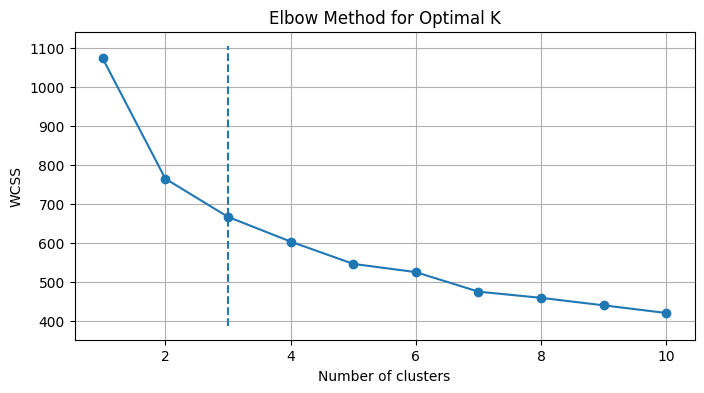

In [169]:
from sklearn.cluster import KMeans
from kneed import KneeLocator
import matplotlib.pyplot as plt


WCSS = []
K_range = range(1, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X)
    WCSS.append(kmeans.inertia_)

knee = KneeLocator(K_range, WCSS, curve='convex', direction='decreasing')

plt.figure(figsize=(8, 4))
plt.plot(K_range, WCSS, marker='o')
plt.title('Elbow Method for Optimal K')
plt.xlabel('Number of clusters')
plt.ylabel('WCSS')
plt.vlines(knee.knee, plt.ylim()[0], plt.ylim()[1], linestyles='dashed')
plt.grid(True)
plt.show()


#### From the graph the optimal K is 3 as the curve is sharp from 1 to 2 and from 2 to 3 then in becomes flatter after 3 indicating that after 3 more clusters provide less improvement

In [170]:
optimal_k = 3
kmeans = KMeans(n_clusters=optimal_k, random_state=42)
kmeans_labels = kmeans.fit_predict(X)

### Visualization

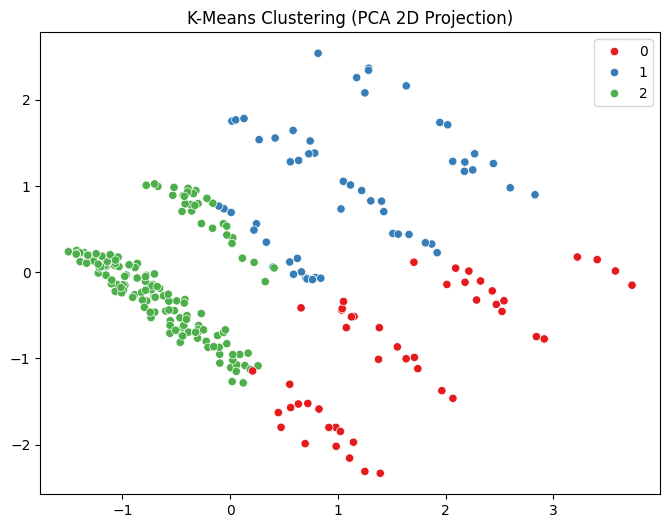

In [171]:
from sklearn.decomposition import PCA
import seaborn as sns

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)
#print(X_pca.explained_variance_ratio_)

# 1st PC 39.37% 
# 2nd PC 19.57%
# 3rd PC 10.9% 
# 4th PC 7.36%
# 5th PC 6.6% 
# 6th PC 6%
# 7th PC 4.13% 
# 8th PC 3.87% 
# 9th PC 2.18%


plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=kmeans_labels, palette='Set1')
plt.title("K-Means Clustering (PCA 2D Projection)")
plt.show()

#### **PCA for Visualization:** By reducing the data to its first two principal components, we retain nearly 60% of the original variance. While this might be low for model training, it's more than adequate to visualize the primary structure and separation of the clusters.
#### **Note on Scatter Plot** The PCA projection reveals four non-spherical clusters, indicating that the K-Means algorithm is unsuitable due to its inherent assumption of circular cluster geometry.

## 2. Perform Hierarchical Clustering (dendrogram analysis). 

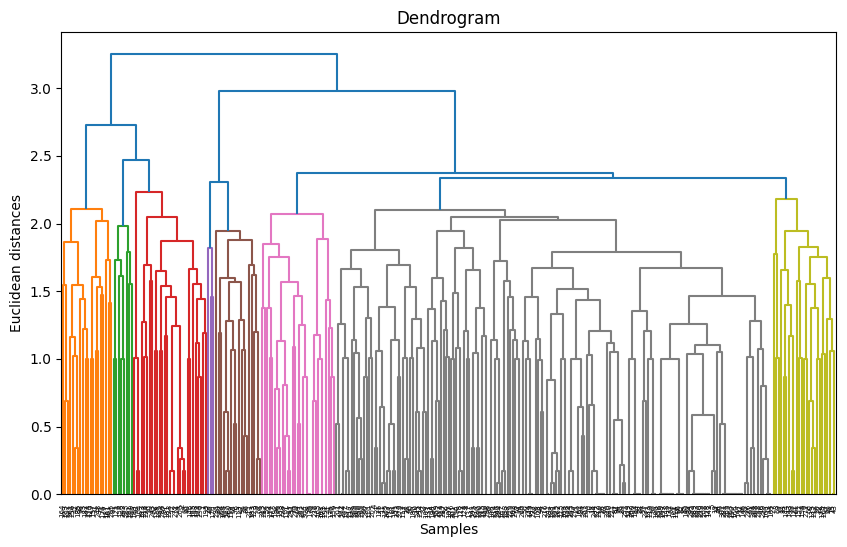

In [172]:
import scipy.cluster.hierarchy as sch

plt.figure(figsize=(10, 6))
dendrogram = sch.dendrogram(sch.linkage(X, method= 'average'))
plt.title('Dendrogram')
plt.xlabel('Samples')
plt.ylabel('Euclidean distances')
plt.show()


The average silhouette_score is: 0.2996


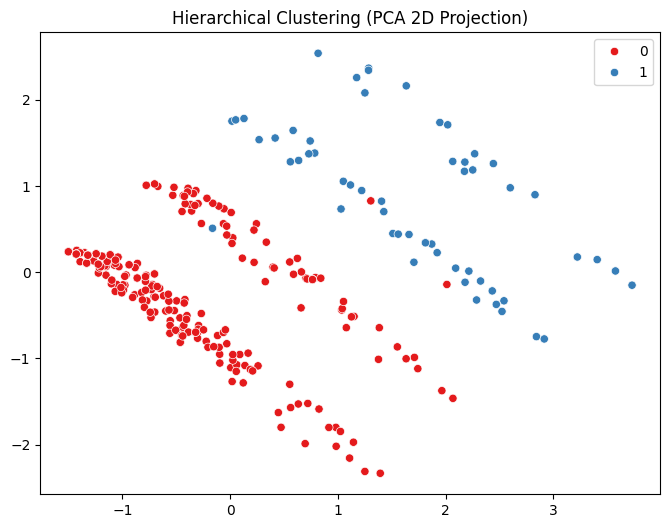

In [173]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

hier_labels = AgglomerativeClustering(n_clusters=2, linkage='average').fit_predict(X)

silhouette_avg = silhouette_score(X, hier_labels)
print(f"The average silhouette_score is: {silhouette_avg:.4f}")
                                  #ward  average
## 2 clusters silhouette score is 0.2993 0.2996
## 3 clusters silhouette score is 0.1950 0.2501

plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=hier_labels, palette='Set1')
plt.title("Hierarchical Clustering (PCA 2D Projection)")
plt.show()


#### After checking the longest distance in the dendogram: clustering into 2 clusters and 3 clusters were comparable so I checked silhouette score which affirmed 2 clusters by having higher score than 3 clusters

## 3. Compare clusters with actual disease labels.

Adjusted Rand Index (K-Means): 0.3387763179166053
Adjusted Rand Index (Hierarchical): 0.09408228381893959


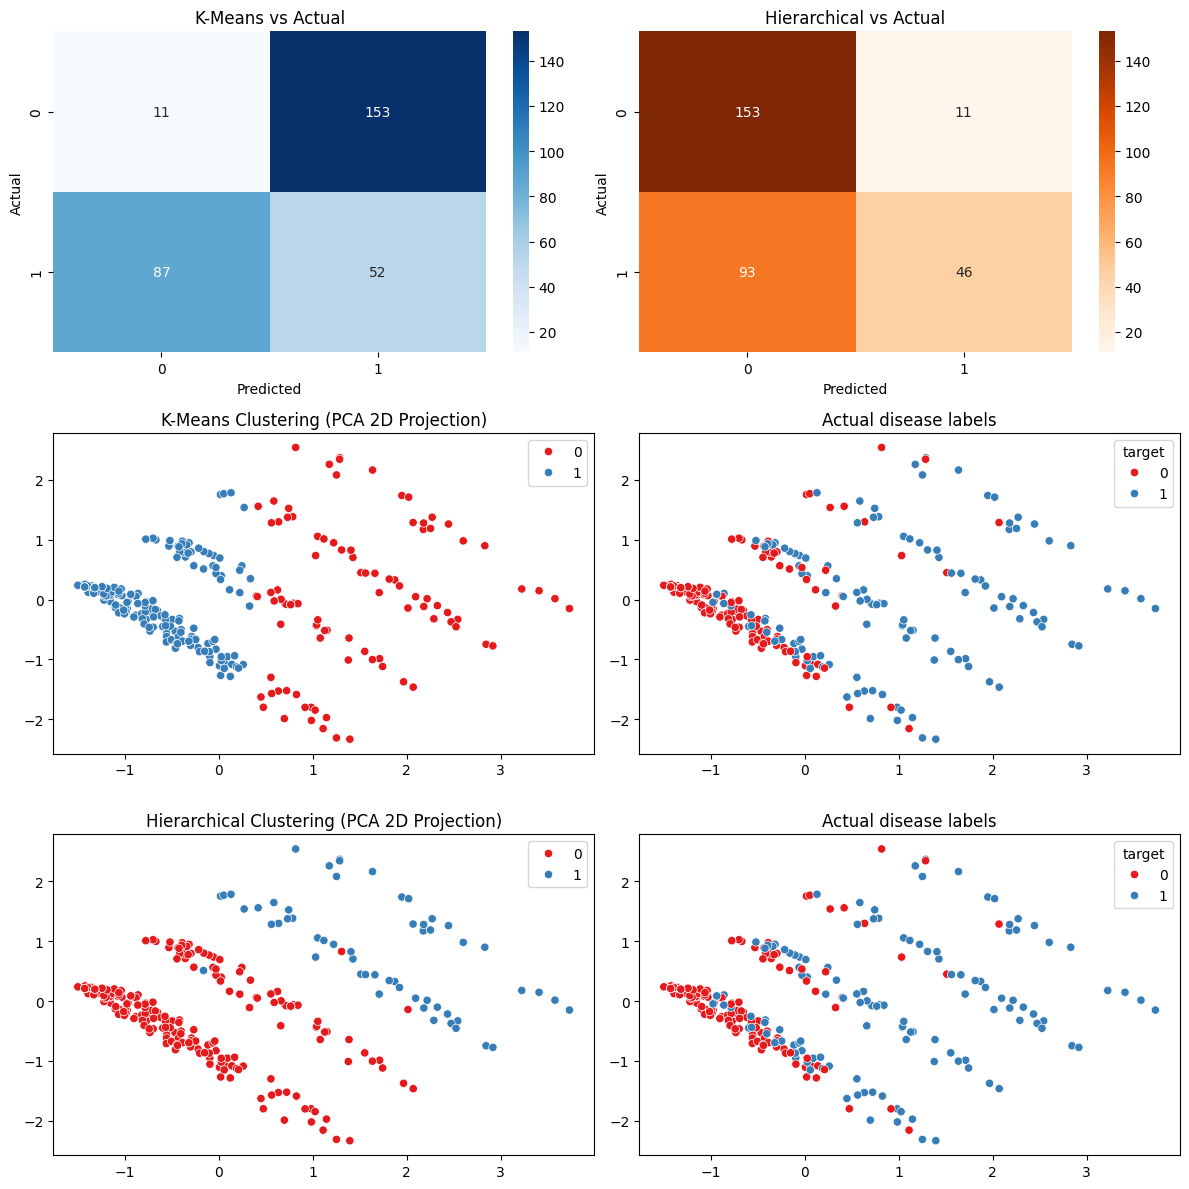

In [174]:
from sklearn.metrics import adjusted_rand_score, confusion_matrix
import seaborn as sns


kmeans = KMeans(n_clusters=2, random_state=42)
kmeans_labels = kmeans.fit_predict(X)

print("Adjusted Rand Index (K-Means):", adjusted_rand_score(y, kmeans_labels))
print("Adjusted Rand Index (Hierarchical):", adjusted_rand_score(y, hier_labels))

cm_kmeans = confusion_matrix(y, kmeans_labels)
cm_hier = confusion_matrix(y, hier_labels)


fig, axes = plt.subplots(3, 2, figsize=(12, 12))


sns.heatmap(cm_kmeans, annot=True, fmt='d', cmap='Blues', ax=axes[0,0])
axes[0,0].set_title("K-Means vs Actual")
axes[0,0].set_xlabel("Predicted")
axes[0,0].set_ylabel("Actual")


sns.heatmap(cm_hier, annot=True, fmt='d', cmap='Oranges', ax=axes[0,1])
axes[0,1].set_title("Hierarchical vs Actual")
axes[0,1].set_xlabel("Predicted")
axes[0,1].set_ylabel("Actual")

sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=kmeans_labels, palette='Set1', ax= axes[1,0])
axes[1,0].set_title("K-Means Clustering (PCA 2D Projection)")

sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=y, palette='Set1', ax= axes[1,1])
axes[1,1].set_title("Actual disease labels")

sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=hier_labels, palette='Set1', ax= axes[2,0])
axes[2,0].set_title("Hierarchical Clustering (PCA 2D Projection)")

sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=y, palette='Set1', ax= axes[2,1])
axes[2,1].set_title("Actual disease labels")



plt.tight_layout()
plt.show()

## K=2 ARI= 0.28
## K=3 ARI= 0.34

###  Clustering Analysis Summary

#### Optimal Number of Clusters (`K`)
- The **Elbow Method** suggests that the optimal number of clusters is **K = 3**.
- However, using **K = 2** produces clusters that visually align more closely with the actual disease labels.
- It also achieves a **higher Adjusted Rand Index (ARI)**.
- This indicates that **K = 2 may better capture the true structure** of the data, despite what the elbow plot suggests.

---

###  Model Comparison: K-Means vs. Hierarchical Clustering

| Metric                        | K-Means | Hierarchical |
|-------------------------------|---------|--------------|
| **Accuracy**                  | **79.2%** | 65.7%        |
| **Adjusted Rand Index (ARI)** | **0.34**  | 0.09         |

- **K-Means** significantly outperforms **Hierarchical Clustering** on both metrics.
- Based on this quantitative evidence, **K-Means is the superior clustering model** for this dataset.

---

###  Interpreting the Confusion Matrix

- Clustering models are **unsupervised**, so the cluster labels they assign (e.g., `0`, `1`, `2`) are **arbitrary** and do not correspond directly to the true class labels.
- To fairly evaluate clustering performance: We **select the diagonal** that gives the **highest possible sum of correct predictions**.
- The goal is to assess **how well the model grouped the data**, not whether it assigned the correct label names.

---
